# Session 6: Tuning K (How much should last season count?)

## Question
In Model v2, last season's xPts per game counts like K extra "virtual games"
(shrinkage). We chose K = 10 by judgement. Is that a good choice?
And is v2 actually better than v1?

Note: v1 is simply **K = 0** (no weight on last season), so one test answers both questions.

## Method: backtest
For every past season with a previous season available (2015/16–2025/26):
1. Freeze time after **8 games**, roughly where the current season is.
2. For each team, project its **remaining** points using a blended xPts rate,
   for several values of K (0, 5, 10, 20, 30, 50).
3. Compare each projection with the points the team actually won from then on.
4. The best K is the one with the **smallest error**.

Promoted teams have no previous Premier League season, so they use only this
season's rate (no shrinkage), as in v2.

## Metric: MAE (Mean Absolute Error)
The average number of points the projection is off by, ignoring the sign.
Example: projected 50, actual 45 → error 5. **Lower is better.**

Why not correlation (r)? r only checks whether teams are in the right *order*.
A projection that adds 20 points to every team would have perfect r but useless
numbers. We want accurate numbers, so we use MAE.

In [38]:
import pandas as pd

SEASON_GAMES = 38
GAMES_PLAYED = 8
GAMES_LEFT = SEASON_GAMES - GAMES_PLAYED     

hist = pd.read_csv("epl_2014_2025_team_matches.csv")
hist["date"]= pd.to_datetime(hist["date"])

hist = hist.sort_values(["team","season","date"],ascending = False)
g = hist.groupby(["team", "season"])

hist["game_no"]=g.cumcount() + 1
hist["xpts_sofar"] = g["xpts"].cumsum()
hist["pts_sofar"]= g["pts"].cumsum()
hist["pts_rest"]=g["pts"].transform("sum") - hist["pts_sofar"]

prior = hist.groupby(["team", "season"])["xpts"].mean().reset_index()
prior["season"] = prior["season"]+1
prior = prior.rename(columns={"xpts": "prior_pg"})

prior.head()

,team,season,prior_pg
0,Arsenal,2015,1.978263
1,Arsenal,2016,2.026545
2,Arsenal,2017,1.634724
3,Arsenal,2018,1.734187
4,Arsenal,2019,1.551876


In [39]:
snap = hist[hist["game_no"] == GAMES_PLAYED].merge(prior, on=["team", "season"], how="left")
snap = snap[snap["season"] >= 2015]

snap["rate_now"] = snap["xpts_sofar"] / GAMES_PLAYED                       # φετινός ρυθμός μετά από 8 ματς
snap["prior_pg"] = snap["prior_pg"].fillna(snap["rate_now"])    # νεοφώτιστες: μόνο φετινά

print(snap.shape)
print(snap["prior_pg"].isna().sum())


(220, 27)
0


In [41]:
results = []
for K in [0, 5, 10, 15, 20,25, 30, 50]:
    rate = (snap["xpts_sofar"] + K * snap["prior_pg"]) / (8 + K)   # ο τύπος του blend
    pred_rest = rate * GAMES_LEFT                                        # πόσα ματς μένουν μετά το 8ο;
    mae = (pred_rest - snap["pts_rest"]).abs().mean()
    results.append({"K": K, "MAE": mae})

tune = pd.DataFrame(results)
print(tune.round(2))

pred_table = snap["pts_sofar"] / GAMES_PLAYED * GAMES_LEFT
print("Table pace MAE:", round((pred_table - snap["pts_rest"]).abs().mean(), 2))
table_mae = (pred_table - snap["pts_rest"]).abs().mean()


    K   MAE
0   0  9.26
1   5  7.83
2  10  7.54
3  15  7.47
4  20  7.44
5  25  7.43
6  30  7.44
7  50  7.50
Table pace MAE: 13.31


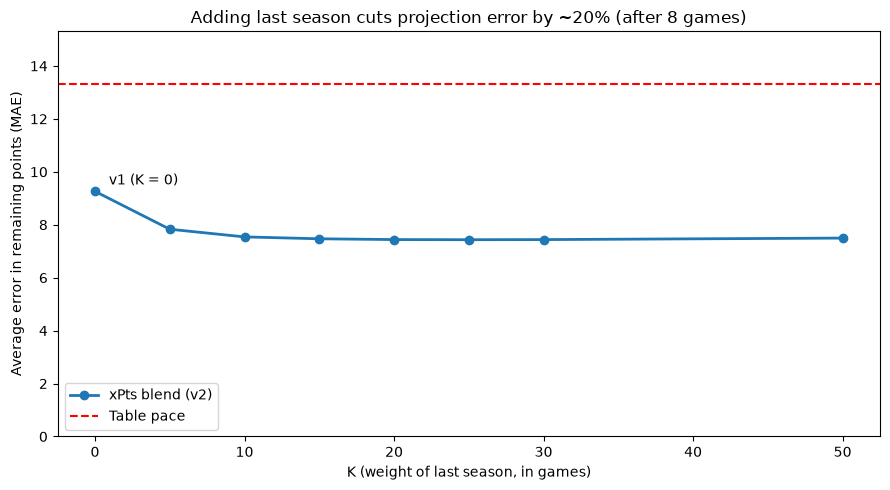

In [51]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

# Η γραμμή του λάθους για κάθε K
ax.plot(tune["K"], tune["MAE"], marker="o", linewidth=2, label="xPts blend (v2)")

# Οριζόντια γραμμή: το λάθος της βαθμολογίας, για σύγκριση
ax.axhline(table_mae, color="red", linestyle="--", label="Table pace")

# Σημείωση στο v1 (K = 0)
v1_mae = tune.loc[tune["K"] == 0, "MAE"].iloc[0]
ax.annotate("v1 (K = 0)", (0, v1_mae), textcoords="offset points", xytext=(10, 5))

ax.set_ylim(0, table_mae + 2)    # ο άξονας y ξεκινάει από το 0
ax.set_title(f"Adding last season cuts projection error by ~20% (after {GAMES_PLAYED} games)")
ax.set_xlabel("K (weight of last season, in games)")
ax.set_ylabel("Average error in remaining points (MAE)")
ax.legend()

plt.tight_layout()
plt.savefig(f"tune_k_after_{GAMES_PLAYED}.png", dpi=150)
plt.show()